# Project on Student Exam Performance Dataset

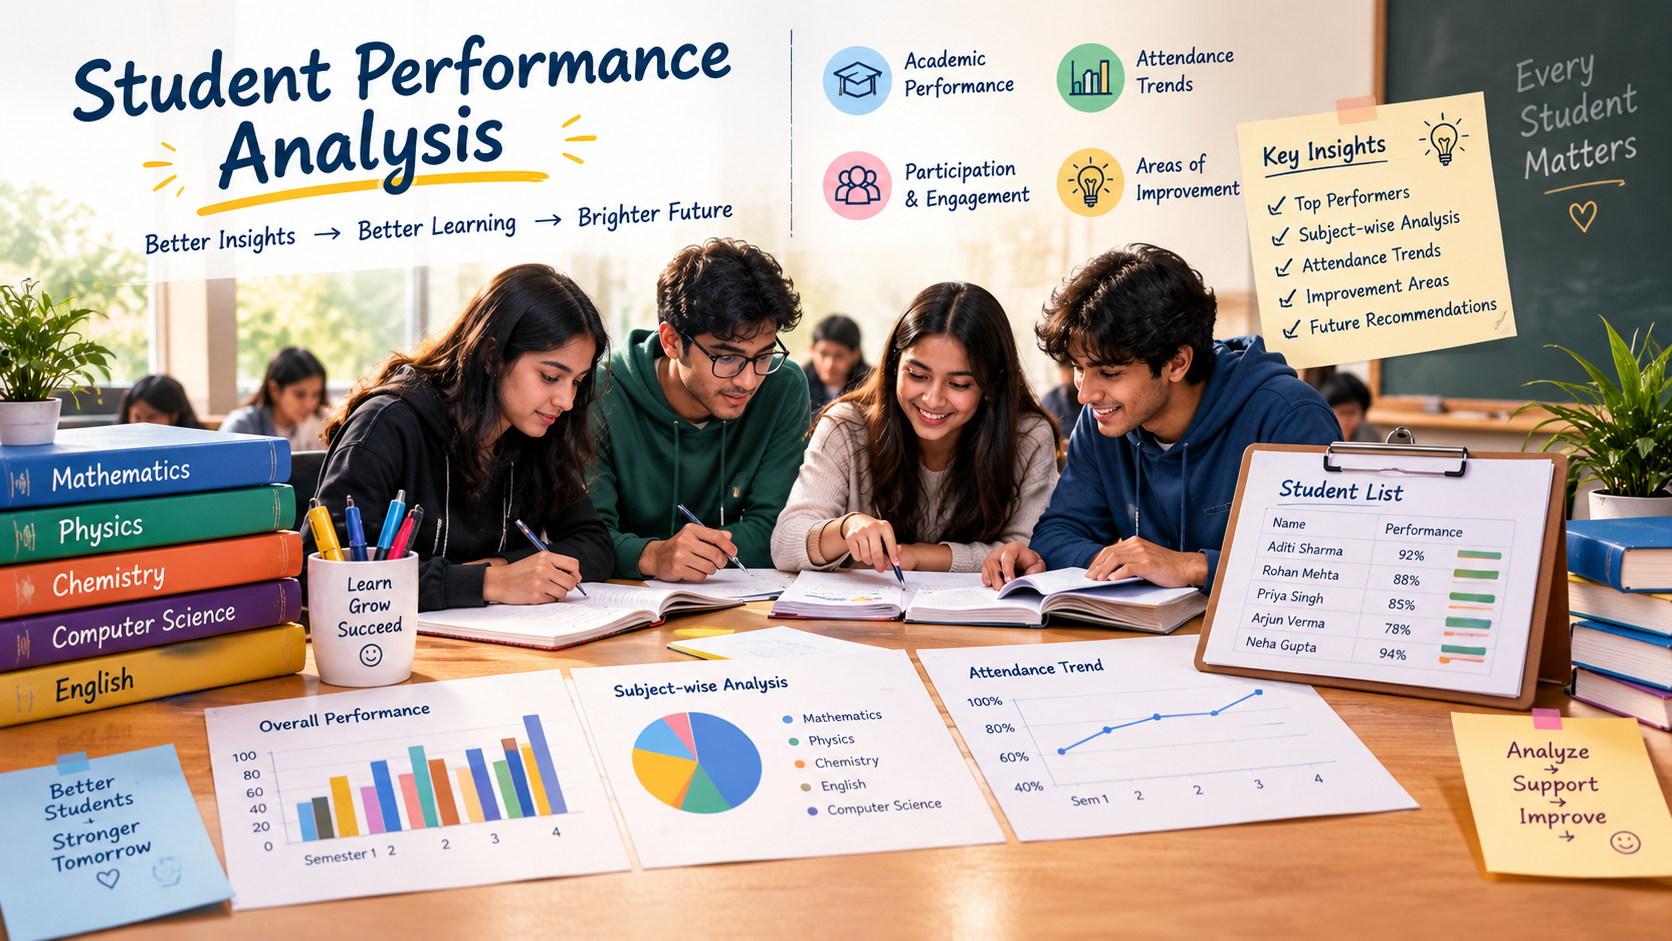

In [49]:

from IPython.display import Image
Image(filename= r"C:\Users\Priyanka\Downloads\ChatGPT Image Oct 2, 2026, 11_50_57 AM.png")

# Dataset Overview

### A school/college wants to get, add, omit and update student information for which they have share the dataset which is as follow:
* The student id and the gender of the student.
* The education level of the student (High School or Undergraduate).
* The exam score (out of 100) and the performance grade (A, B, C, D).
* Based on this analysis, a model can later be designed to predict a student's performance grade.

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [4]:
DATA_PATH = r"C:\Users\Priyanka\Downloads\student_exam_performance-selected-columns.csv.crswap"
df = pd.read_csv(DATA_PATH)
df

,student_id,gender,education_level,exam_score,performance_grade
0,STU_000001,Female,High School,90.40,A
1,STU_000002,Male,High School,86.21,A
2,STU_000003,Other,Undergraduate,76.11,B
3,STU_000004,Male,High School,79.74,B
4,STU_000005,Female,High School,50.66,D
...,...,...,...,...,...
38831,STU_038832,Male,Undergraduate,73.00,C
38832,STU_038833,Female,Undergraduate,98.62,A
38833,STU_038834,Male,High School,64.98,D
38834,STU_038835,Female,Undergraduate,57.74,D


In [5]:
df.head()

,student_id,gender,education_level,exam_score,performance_grade
0,STU_000001,Female,High School,90.40,A
1,STU_000002,Male,High School,86.21,A
2,STU_000003,Other,Undergraduate,76.11,B
3,STU_000004,Male,High School,79.74,B
4,STU_000005,Female,High School,50.66,D


In [22]:
df.tail(10)

,student_id,gender,education_level,exam_score,performance_grade
38826,STU_038827,Male,High School,70.47,C
38827,STU_038828,Male,Undergraduate,64.82,D
38828,STU_038829,Male,High School,79.79,B
38829,STU_038830,Female,High School,63.94,D
38830,STU_038831,Female,Undergraduate,64.11,D
38831,STU_038832,Male,Undergraduate,73.00,C
38832,STU_038833,Female,Undergraduate,98.62,A
38833,STU_038834,Male,High School,64.98,D
38834,STU_038835,Female,Undergraduate,57.74,D
38835,STU_038836,Male,High School,56.40,D


In [6]:
df.shape

(38836, 5)

# Contents of data

In [13]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 38836 entries, 0 to 38835
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   student_id         38836 non-null  str    
 1   gender             38836 non-null  str    
 2   education_level    38836 non-null  str    
 3   exam_score         38836 non-null  float64
 4   performance_grade  38836 non-null  str    
dtypes: float64(1), str(4)
memory usage: 2.5 MB


In [12]:
df.isna().sum()

student_id           0
gender               0
education_level      0
exam_score           0
performance_grade    0
dtype: int64

In [11]:
df.columns

Index(['student_id', 'gender', 'education_level', 'exam_score',
       'performance_grade'],
      dtype='str')

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
exam_score,38836.0,61.94838,15.801317,0.0,51.27,61.955,72.72,100.0


In [8]:
df.student_id.describe()

count          38836
unique         38836
top       STU_000001
freq               1
Name: student_id, dtype: object

In [7]:
df.duplicated().value_counts()

False    38836
Name: count, dtype: int64

#### Duplicate check: if the count shows only False, the dataset has no duplicate rows.

In [14]:
df.duplicated(subset=['student_id']).value_counts()

False    38836
Name: count, dtype: int64

##### If only `False` is shown, every student_id is unique.

# Data information and preprocessing

In [48]:
new_student = {'student_id': "MNIT123","gender": "Female","education_level": "Undergraduate","exam_score": 98,'performance_grade': 'A'}

if "MNIT123" not in df["student_id"].values:
    df = pd.concat([df, pd.DataFrame([new_student])], ignore_index=True)
df = df.drop_duplicates(subset=["student_id"], keep="last")
#df.to_csv(r"C:\Users\Priyanka\Downloads\student_exam_performance-selected-columns.csv.crswap", index=False)
df


,student_id,gender,education_level,exam_score,performance_grade,grade
0,STU_000001,Female,High School,90.40,A,NaN
1,STU_000002,Male,High School,86.21,A,NaN
2,STU_000003,Other,Undergraduate,76.11,B,NaN
3,STU_000004,Male,High School,79.74,B,NaN
4,STU_000005,Female,High School,50.66,D,NaN
...,...,...,...,...,...,...
38832,STU_038833,Female,Undergraduate,98.62,A,NaN
38833,STU_038834,Male,High School,64.98,D,NaN
38834,STU_038835,Female,Undergraduate,57.74,D,NaN
38835,STU_038836,Male,High School,56.40,D,NaN


In [33]:
df.student_id

0        STU_000001
1        STU_000002
2        STU_000003
3        STU_000004
4        STU_000005
            ...    
38832    STU_038833
38833    STU_038834
38834    STU_038835
38835    STU_038836
38837       MNIT123
Name: student_id, Length: 38837, dtype: str

In [34]:
search_id = "MNIT123"
result = df[df["student_id"] == search_id]

if not result.empty:
    print(result)
else:
    print("Student not found")


      student_id  gender education_level  exam_score performance_grade
38837    MNIT123  Female   Undergraduate        98.0                 A


In [35]:

df.groupby('performance_grade')['exam_score'].agg(['min', 'max', 'mean', 'count'])

,min,max,mean,count
performance_grade,,,,
A,85.0,100.00,91.640253,2889
B,75.0,84.99,79.345505,5117
C,65.0,74.99,69.762142,8466
D,50.0,64.99,57.815985,13633
F,0.0,49.99,40.810127,8732


##### The table above shows the lowest and highest score for every grade, so we can understand how grades are given.

## Updating student detail

In [38]:
def update_student(student_id, column, new_value):
    if student_id in df["student_id"].values:
        df.loc[df["student_id"] == student_id, column] = new_value
        print(f"Updated {student_id}: {column} -> {new_value}")
    else:
        print("Student not found")
update_student("MNIT123", "exam_score", 100)

Updated MNIT123: exam_score -> 100


## Delete student

In [43]:
def delete_student(student_id):
    global df
    if student_id in df["student_id"].values:
        df = df[df["student_id"] != student_id]
        print(f"Deleted {student_id}")
    else:
        print("Student not found")
delete_student('2024uch1990')        

Student not found


## Calculate average marks

In [44]:
def average_marks():
    avg = df["exam_score"].mean()
    print(f"Average Exam Score: {avg:.2f}")
    return avg

average_marks()

Average Exam Score: 61.95


np.float64(61.94935963127944)

## Save records

In [47]:
df.to_csv("students_updated.csv", index=False)
print("Records saved to students_updated.csv")

Records saved to students_updated.csv


# Reference

##### Kagggle:https://www.kaggle.com/datasets/mobeenfatimah/student-exam-performance-and-success-dataset